# 13. 最小二乗法による「逆カーネル」と、奥行きで変わるピンボケの復元

**セミナー対応章**：第5章（3）　｜　**推奨ランタイム**：Colab無料枠 T4 GPU　｜　**所要時間**：約5分（CNN の比較を含めると +8〜15分）

1. **講師の手法の再現**（PSF が一定の場合）：ボケ画像の 15×15 画素から、鮮明画像の中心画素を予測する **線形フィルタ（＝PSF の逆カーネル）を最小二乗法で学習** する。
   論文と同じ条件（ガウスぼけ σ=1.5、学習画像 3 枚）で、Wiener フィルタと比べる
   （T. Nagata, "Fast Blind Deconvolution with Simple Machine Learning", Proc. 7th Asia Int. Symp. on Mechatronics, Springer, 2020）
2. **奥行きで PSF が変わる場合**：深層学習で奥行きを推定 → 場所ごとのボケの大きさ σ を求め、**σ 別に学習した逆カーネルを場所ごとに切り替えて** 復元する
3. **奥行き推定の誤差まで含めて学習**：推定 σ ごとに「どの逆カーネルをどれだけ混ぜるか」も最小二乗法で学習する
4. 比較：Wiener フィルタ（固定／場所ごと）、画素ごとに直接予測する CNN（同じ学習画像 3 枚）

**関連する先行研究**（「場所ごとのボケの大きさを推定 → 場所ごとに復元」と「画素ごとに直接予測する CNN」）
- JNB（Shi+, CVPR 2015）、EBDB（Karaali+, TIP 2018）、DMENet（Lee+, CVPR 2019）：ボケの大きさのマップを推定してから、場所ごとに逆畳み込み
- DPDNet（Abuolaim & Brown, ECCV 2020）：画素ごとに直接予測する CNN。DPDD データセットで上記の 2 段階法を 0.5〜0.7 dB 上回った
- J. Lee et al., *IFAN*, CVPR 2021／H. Son et al., *KPAC*, ICCV 2021：画素ごとのデブラー用フィルタ（逆カーネル）を CNN で予測
- Y. Quan et al., *Implicit Neural Inverse Kernels*, ICCV 2023：逆カーネルを辞書の線形結合で表し、構造的な制約を加える
- K. Yanny et al., *MultiWienerNet*, Optica 2022：場所ごとに異なる PSF を、複数の Wiener フィルタの重み付き和で扱う（顕微鏡）

画像：Kodak 標準テスト画像（r0k.us/graphics/kodak/）。奥行き推定：Depth Anything V2 Small（Apache 2.0）

In [1]:
# ===== 共通セットアップ（このセルを最初に1回だけ実行してください） =====
import os, sys, subprocess, time, urllib.request

IN_COLAB = "google.colab" in sys.modules

def pip_install(*pkgs):
    """足りないライブラリを静かにインストールする（Colab用）"""
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

if IN_COLAB:
    # Colabには torch / transformers / diffusers などが最初から入っています。
    # 不足分だけ追加します（1〜2分）。
    pip_install("spandrel", "lpips", "diffusers>=0.30", "accelerate", "peft")

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"実行環境: {'Google Colab' if IN_COLAB else 'ローカルPC'} / torch {torch.__version__}")
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  VRAM: {p.total_memory / 1024**3:.1f} GB")
else:
    print("GPUが見つかりません。Colabでは［ランタイム］→［ランタイムのタイプを変更］→ T4 GPU を選んでください。")

WEIGHTS_DIR = os.path.abspath("weights")
os.makedirs(WEIGHTS_DIR, exist_ok=True)

def download(url, name=None):
    """学習済み重みをダウンロード（2回目以降はキャッシュを使う）"""
    path = os.path.join(WEIGHTS_DIR, name or url.split("/")[-1])
    if not os.path.exists(path):
        print("downloading", url)
        urllib.request.urlretrieve(url, path)
    return path

def load_sample(name="astronaut", size=None):
    """scikit-image同梱のサンプル画像（ネット不要）。name: astronaut / coffee / chelsea / rocket"""
    from skimage import data
    img = Image.fromarray(getattr(data, name)()).convert("RGB")
    if size:
        img = img.resize((size, size) if isinstance(size, int) else size, Image.BICUBIC)
    return img

def load_portrait():
    """顔が大きく写った 512x512 の高画質画像（Kodak 標準テスト画像 kodim04 の上部を切り出し）。
    Kodak 画像は画像処理の評価用に広く使われているフリーのテスト画像（r0k.us/graphics/kodak/）。
    ダウンロードできない場合は astronaut で代用。"""
    try:
        img = Image.open(download("https://r0k.us/graphics/kodak/kodak/kodim04.png")).convert("RGB")
        return img.crop((0, 160, 512, 672))
    except Exception as e:
        print("kodim04 を取得できなかったため astronaut を使います:", e)
        return load_sample("astronaut")

def to_np(img):
    """PIL → float32 [0,1] の (H,W,3) 配列"""
    return np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

def to_pil(arr):
    return Image.fromarray((np.clip(arr, 0, 1) * 255 + 0.5).astype(np.uint8))

def to_tensor(img):
    """PIL / ndarray → (1,3,H,W) テンソル"""
    a = to_np(img) if isinstance(img, Image.Image) else img
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)).permute(2, 0, 1)[None].contiguous()

def tensor_to_pil(t):
    return to_pil(t[0].detach().float().clamp(0, 1).permute(1, 2, 0).cpu().numpy())

def psnr(a, b):
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))

def ssim(a, b):
    from skimage.metrics import structural_similarity
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return structural_similarity(a, b, channel_axis=2, data_range=1.0)

def show(images, titles=None, size=4, rows=1):
    """画像を横に並べて表示（タイトルは文字化け防止のため英数字推奨）"""
    n = len(images)
    cols = (n + rows - 1) // rows
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            im = images[i]
            if isinstance(im, np.ndarray) and im.ndim == 2:
                ax.imshow(im, cmap="gray")                      # 2次元配列（マップ・スペクトル）は自動スケール
            else:
                if isinstance(im, np.ndarray) and im.dtype != np.uint8:
                    im = np.clip(im, 0, 1)                      # float 画像は 0〜1 に収める
                ax.imshow(im)
            if titles:
                ax.set_title(titles[i], fontsize=11)
    plt.tight_layout()
    plt.show()

def gpu_mem():
    if DEVICE == "cuda":
        print(f"GPUメモリ使用量(ピーク): {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

実行環境: ローカルPC / torch 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5090 Laptop GPU  VRAM: 23.9 GB


## 1. 講師の論文の再現：PSF が一定の場合
- 学習：Kodak の 3 枚（01, 13, 23）をボケさせ、15×15 画素 → 中心画素 の組を約 22 万個作って最小二乗法で解く（論文と同じ規模）
- 論文の工夫：ブロックごとに平均を引き標準偏差で割ってから学習（明るさ・コントラストの違いを吸収）。結果は同じく 15×15 の線形フィルタになる
- 比較する Wiener フィルタは、**論文と同じく 15×15 の空間フィルタ** にしたもの（＋参考に大きさ無制限の FFT 版）。λ はテスト画像ごとに最良の値を探す（Wiener に有利な条件）
- 実際のボケが **Wiener の仮定（ガウス）と違う場合**（円盤状のピンボケ）も試す。Wiener はガウスの σ と λ をテスト画像で最良に選ぶ

ボケ画像は論文と同じく 8 bit に量子化するだけで、ノイズは加えません。

In [2]:
import cv2

KODAK = "https://r0k.us/graphics/kodak/kodak/kodim{}.png"
load = lambda n: to_np(Image.open(download(KODAK.format(n))))
TRAIN, TESTS = ["01", "13", "23"], ["05", "08", "21"]     # 学習は 3 枚だけ（講師の論文と同じ考え方）
train_imgs = [load(t) for t in TRAIN]
test_imgs = {t: load(t) for t in TESTS}
q8 = lambda x: (np.round(np.clip(x, 0, 1) * 255) / 255).astype(np.float32)
c = slice(24, -24)                                          # 画像の端は評価から除く
P = lambda a, g: psnr(np.clip(a, 0, 1)[c, c], g[c, c])

def apply_kernel(b, k):
    return cv2.filter2D(b, -1, k.astype(np.float32), borderType=cv2.BORDER_REFLECT)

def gauss_psf(s):
    r = int(np.ceil(4 * s)); g = cv2.getGaussianKernel(2 * r + 1, s); return (g @ g.T).astype(np.float32)

def disk_psf(rad):
    k = np.zeros((2 * rad + 1,) * 2, np.float32); cv2.circle(k, (rad, rad), rad, 1, -1); return k / k.sum()

def sample_patches(pairs, n_each, ks, seed=0):
    """ボケ画像の ks×ks 画素（説明変数）と、鮮明画像の中心画素（目的変数）の組をランダムに取り出す"""
    rng = np.random.default_rng(seed); r = ks // 2; idx = np.arange(-r, r + 1)
    Xs, ys = [], []
    for b, x in pairs:
        H, W = b.shape[:2]
        yy, xx, cc = rng.integers(r, H - r, n_each), rng.integers(r, W - r, n_each), rng.integers(0, 3, n_each)
        Xs.append(b[yy[:, None, None] + idx[None, :, None], xx[:, None, None] + idx[None, None, :], cc[:, None, None]].reshape(n_each, -1))
        ys.append(x[yy, xx, cc])
    return np.concatenate(Xs).astype(np.float64), np.concatenate(ys).astype(np.float64)

def ls_kernel(pairs, ks, n_each=40000, lam=1e-3, standardize=False, seed=0):
    """最小二乗法で逆カーネルを求める（係数を ks×ks に並べたものがフィルタ）"""
    X, y = sample_patches(pairs, n_each, ks, seed)
    if standardize:                                         # 論文：ブロックごとに標準化し、目的変数は p − p'
        m, s = X.mean(1, keepdims=True), X.std(1, keepdims=True) + 1e-3
        Z = (X - m) / s; ci = ks * ks // 2
        t = (y - m[:, 0]) / s[:, 0] - Z[:, ci]
        w = np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ t)
        k = w - w.sum() / ks ** 2; k[ci] += 1                # 予測 = x_c + w·(x − 平均) なので、同じ働きの線形フィルタに直せる
    else:
        k = np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ y)
    return k.reshape(ks, ks).astype(np.float32)

def otf(k, shape):                                          # PSF の周波数応答
    p = np.zeros(shape, np.float32); p[:k.shape[0], :k.shape[1]] = k
    return np.fft.fft2(np.roll(p, (-(k.shape[0] // 2), -(k.shape[1] // 2)), (0, 1)))

def wiener_full(b, k, lam, pad=48):                         # 大きさ無制限の Wiener（FFT）
    bp = cv2.copyMakeBorder(b, pad, pad, pad, pad, cv2.BORDER_REFLECT)
    Kf = otf(k, bp.shape[:2]); Hf = np.conj(Kf) / (np.abs(Kf) ** 2 + lam)
    return np.stack([np.real(np.fft.ifft2(np.fft.fft2(bp[..., i]) * Hf)) for i in range(3)], -1)[pad:-pad, pad:-pad]

def wiener_kernel(k, lam, n, size=256):                     # Wiener を n×n の空間フィルタにしたもの（論文の比較対象）
    Kf = otf(k, (size, size)); h = np.fft.fftshift(np.real(np.fft.ifft2(np.conj(Kf) / (np.abs(Kf) ** 2 + lam))))
    m = size // 2; h = h[m - n // 2:m + n // 2 + 1, m - n // 2:m + n // 2 + 1]
    return h / h.sum()                                      # 打ち切ると明るさ（直流成分）がずれるので、合計 1 に直す（Wiener に有利な補正）

N15, LAMS, GSIG = 15, 10.0 ** np.arange(-6, -0.9, 0.25), np.arange(1.0, 2.51, 0.25)
paper, paper_imgs = {}, {}                                  # paper_imgs：画像 05 の復元結果（あとで表示する）
for case, true_psf in {"Gaussian sigma=1.5": gauss_psf(1.5), "disk r=3 (defocus)": disk_psf(3)}.items():
    deg = lambda x: q8(apply_kernel(x, true_psf))
    pairs = [(deg(x), x) for x in train_imgs]
    k_ls = ls_kernel(pairs, N15, n_each=74000)
    k_std = ls_kernel(pairs, N15, n_each=74000, standardize=True)
    rows = {}
    for t, g in test_imgs.items():
        b = deg(g)
        # Wiener：ガウス PSF を仮定し、σ と λ をテスト画像で最良に選ぶ
        sg, lm = max(((s, l) for s in GSIG for l in LAMS), key=lambda p: P(wiener_full(b, gauss_psf(p[0]), p[1]), g))
        best = lambda outs: max(outs, key=lambda o: P(o, g))   # λ を変えた結果のうち、最も PSNR の高いもの
        imgs = {"input": b,
                "LS 15x15": apply_kernel(b, k_ls),
                "LS 15x15, block-standardized (paper)": apply_kernel(b, k_std),
                "Wiener 15x15 (Gaussian assumed)": best(apply_kernel(b, wiener_kernel(gauss_psf(sg), l, N15)) for l in LAMS),
                "Wiener full FFT (Gaussian assumed)": wiener_full(b, gauss_psf(sg), lm),
                "Wiener full FFT (exact PSF, reference)": best(wiener_full(b, true_psf, l) for l in LAMS)}
        rows[t] = {n: P(o, g) for n, o in imgs.items()}
        if t == "05":
            paper_imgs[case] = imgs
    paper[case] = rows
    print(f"\n[{case}]  PSNR (dB)        " + "  ".join(TESTS) + "   mean")
    for name in rows[TESTS[0]]:
        v = [rows[t][name] for t in TESTS]
        print(f"  {name:40s} " + " ".join(f"{a:5.2f}" for a in v) + f"  {np.mean(v):5.2f}")
    if case.startswith("Gaussian"):
        kernels_paper = (k_ls, k_std, wiener_kernel(gauss_psf(1.5), 10 ** -3.5, N15))


[Gaussian sigma=1.5]  PSNR (dB)        05  08  21   mean
  input                                    22.76 20.58 25.40  22.92
  LS 15x15                                 28.37 25.99 29.89  28.08
  LS 15x15, block-standardized (paper)     27.15 24.66 29.27  27.03
  Wiener 15x15 (Gaussian assumed)          26.99 24.49 29.03  26.84
  Wiener full FFT (Gaussian assumed)       28.49 26.16 29.92  28.19
  Wiener full FFT (exact PSF, reference)   28.49 26.16 29.92  28.19



[disk r=3 (defocus)]  PSNR (dB)        05  08  21   mean
  input                                    21.70 19.63 24.45  21.93
  LS 15x15                                 27.20 24.70 29.44  27.11
  LS 15x15, block-standardized (paper)     26.78 24.28 29.17  26.75
  Wiener 15x15 (Gaussian assumed)          22.96 20.70 25.54  23.07
  Wiener full FFT (Gaussian assumed)       23.12 20.81 25.55  23.16
  Wiener full FFT (exact PSF, reference)   31.23 29.63 32.78  31.21


**結果の読み方**
- **同じ 15×15 の大きさ** で比べると、最小二乗の逆カーネルは Wiener を上回る（論文の比較条件）。Wiener の理論解は本来無限に広がるので、15×15 で打ち切ると損をする。
  最小二乗法は「15×15 という制約の中での最適」を直接求める
- 実際のボケが **ガウスでない（円盤状のピンボケ）** と、ガウスを仮定した Wiener は大きく崩れるが、最小二乗法はデータから学ぶので影響を受けない。
  論文で 4〜6 dB の差がついたのは、このような「仮定した PSF と実際のボケのずれ」が効いていると考えられる
- ガウスぼけでは、PSF を **正確に** 与え大きさ無制限にした理想的な Wiener（最下行）とほぼ同等。逆カーネルは PSF の式を知らずに、データだけでこの理論上の上限に近づく。
  円盤状のボケでは、PSF の形まで正確に分かっていれば理想的な Wiener がさらに上だが、逆カーネルも大きくすると近づく（21×21 で約 28.1 dB、31×31 で約 29.1 dB）
- ブロックごとの標準化（論文の工夫）は、明るさやコントラストに依らず誤差を均等に扱うため、PSNR（2 乗誤差）では素の最小二乗とわずかに差が出る

**復元した画像**（テスト画像 05 の一部を拡大。数値は画像全体の PSNR）
- 上段：ガウスぼけ（σ=1.5）。ボケが小さいので、差は細かい模様や輪郭に出る
- 下段：円盤状のピンボケ（半径 3 画素）。ガウスを仮定した Wiener と、データから学んだ逆カーネルの差が大きくなる

Gaussian sigma=1.5


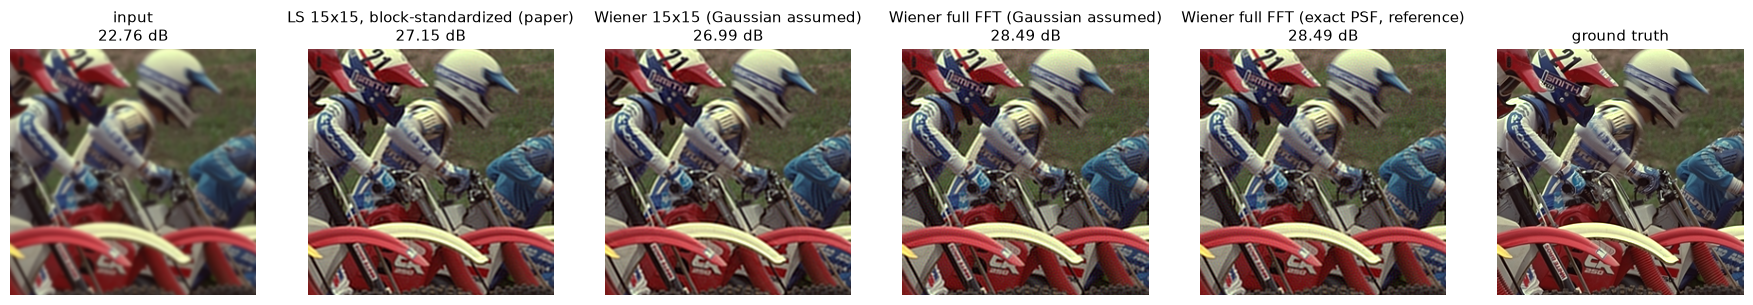

disk r=3 (defocus)


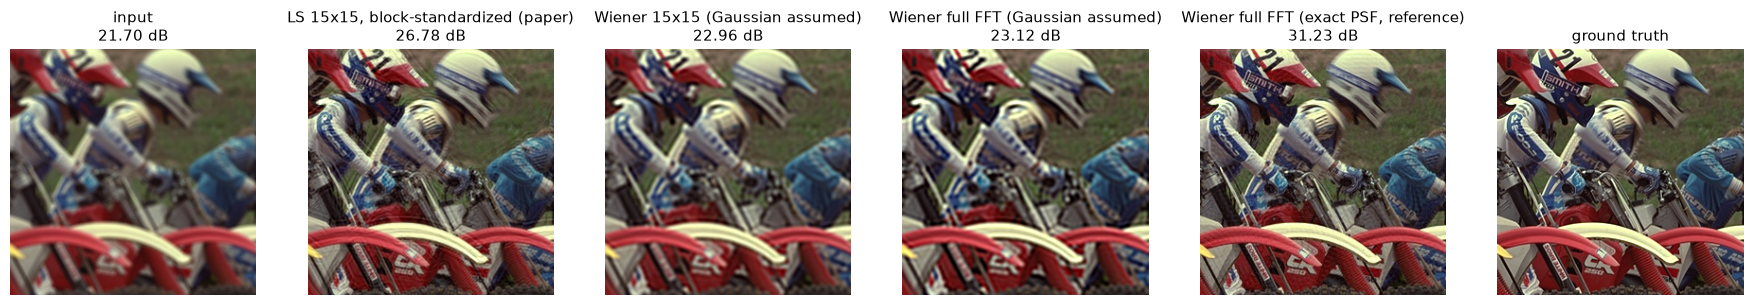

In [3]:
g05 = test_imgs["05"]
box1 = (slice(30, 290), slice(380, 640))                   # 5. と同じ場所を拡大
cols = ["input", "LS 15x15, block-standardized (paper)", "Wiener 15x15 (Gaussian assumed)",
        "Wiener full FFT (Gaussian assumed)", "Wiener full FFT (exact PSF, reference)"]
for case, imgs in paper_imgs.items():
    print(case)
    show([np.clip(imgs[n][box1], 0, 1) for n in cols] + [g05[box1]],
         [f"{n}\n{P(imgs[n], g05):.2f} dB" for n in cols] + ["ground truth"], size=3.0)

**学習した逆カーネル**（15×15 の係数を画像として表示）。最小二乗の逆カーネルは、Wiener を 15×15 で打ち切ったものとよく似た形になる

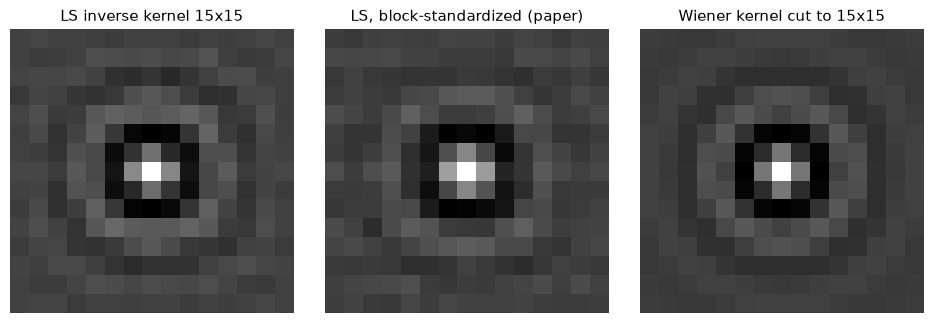

In [4]:
show([kernels_paper[0], kernels_paper[1], kernels_paper[2]],
     ["LS inverse kernel 15x15", "LS, block-standardized (paper)", "Wiener kernel cut to 15x15"], size=3.2)

## 2. 奥行きで変わるピンボケを作る
薄肉レンズでは、ボケの直径は **視差（奥行きの逆数）とピント位置の視差の差** に比例します。
奥行き推定 AI の出力は視差に相当するので、ボケの大きさ σ（ガウスぼけの標準偏差）を σ = A·|D − D_f| とします。
ここでは、最も手前（D_f = 1）にピントを合わせ、最も遠い所で σ = 4 画素とします。ノイズ（σ=0.005）も加えます。

W1103 11:07:37.410000 21676 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

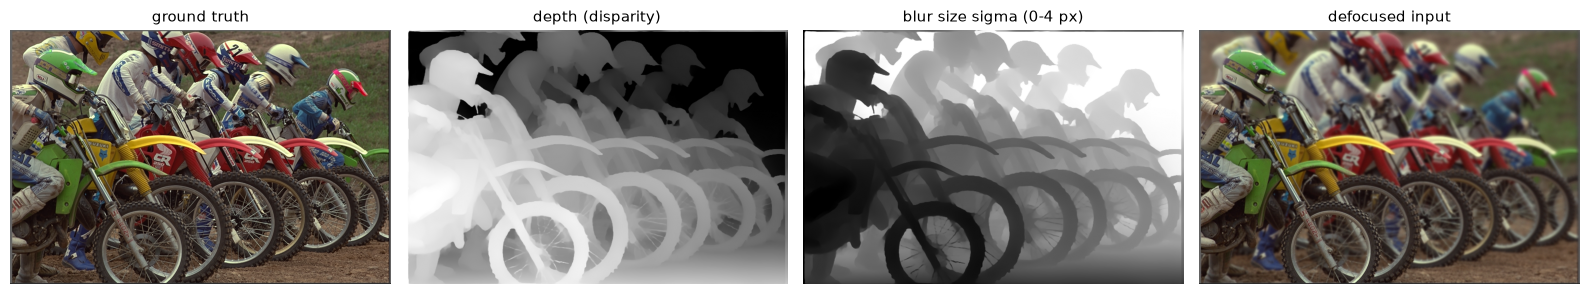

In [5]:
from transformers import pipeline

A, DF, NOISE = 4.0, 1.0, 0.005
depth_pipe = pipeline("depth-estimation", model="depth-anything/Depth-Anything-V2-Small-hf", device=0 if DEVICE == "cuda" else -1)

def disparity(img, top=99):
    """奥行き推定 AI の出力（視差：大きいほど手前）を 0〜1 に正規化"""
    d = np.asarray(depth_pipe(to_pil(img))["predicted_depth"], np.float32)
    d = cv2.resize(d, img.shape[1::-1], interpolation=cv2.INTER_CUBIC)
    lo, hi = np.percentile(d, 1), np.percentile(d, top)
    return np.clip((d - lo) / (hi - lo), 0, 1)

def gblur(x, s):
    return x if s < 1e-3 else cv2.GaussianBlur(x, (0, 0), s, borderType=cv2.BORDER_REFLECT)

def sv_blur(x, smap, step=0.1):
    """場所ごとに σ が違うボケ（σ を細かい段階に分け、隣り合う段階を線形補間）"""
    out = np.zeros_like(x)
    for s in np.arange(0, smap.max() + step, step):
        w = np.clip(1 - np.abs(smap - s) / step, 0, 1)[..., None]
        if w.max() > 0:
            out += w * gblur(x, s)
    return out

def add_noise(x, seed=0):
    return np.round(np.clip(x + np.random.default_rng(seed).normal(0, NOISE, x.shape), 0, 1) * 255) / 255

scenes = {}
for t, g in test_imgs.items():
    D_true = disparity(g)                                   # 「正解の奥行き」（鮮明画像から推定したものを正解とみなす）
    smap = A * np.abs(D_true - DF)
    scenes[t] = dict(gt=g, D=D_true, smap=smap, blur=add_noise(sv_blur(g, smap)))
s05 = scenes["05"]
show([s05["gt"], s05["D"], s05["smap"], s05["blur"]], ["ground truth", "depth (disparity)", "blur size sigma (0-4 px)", "defocused input"], size=4)

## 3. σ 別の逆カーネルを用意し、奥行きから場所ごとに切り替える
1. ボケの大きさ σ = 0, 0.25, …, 4 の 17 段階それぞれで、21×21 の逆カーネルを最小二乗法で学習する（一様なボケ・学習画像 3 枚）
2. **ボケ画像から** 奥行きを推定し、少しぼかして滑らかにする ＝「近くの場所の逆カーネルは似ている」という制約
3. 奥行き → σ（カメラのピント位置・絞りは既知とする）
4. σ に応じて、隣り合う 2 つの逆カーネルの結果を線形補間（逆カーネル自体を場所ごとに滑らかに補間するのと同じ）

In [6]:
KS = 21
LEVELS = np.arange(0, 4.01, 0.25)
t0 = time.time()
kernels = [ls_kernel([(add_noise(gblur(x, s), seed=100 + k), x) for k, x in enumerate(train_imgs)], KS, seed=int(s * 100)) for s in LEVELS]
print(f"逆カーネル {len(kernels)} 個（各 {KS}x{KS}）を学習: {time.time()-t0:.0f}s")

def best_K(sig):                                 # Wiener の定数 K も、学習画像で最良の値を選ぶ（公平な比較のため）
    if sig < 1e-3: return 1.0
    bs = [add_noise(gblur(x, sig), seed=100 + k) for k, x in enumerate(train_imgs)]
    return max([1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2], key=lambda K: np.mean([P(wiener_full(b, gauss_psf(sig), K), x) for b, x in zip(bs, train_imgs)]))
Ks = [best_K(s) for s in LEVELS]
wiener_at = lambda b, s, K: b if s < 1e-3 else wiener_full(b, gauss_psf(s), K)

def est_sigma(blur, df=DF):
    """ボケ画像から奥行きを推定 → 平滑化 → σ"""
    return A * np.abs(cv2.GaussianBlur(disparity(blur), (0, 0), 4) - df)

def bin_weights(s):
    """σ に対する各段階の補間の重み（H×W×17、隣り合う 2 段階だけが 0 でない）"""
    st = LEVELS[1] - LEVELS[0]; s = np.clip(s, LEVELS[0], LEVELS[-1])
    return np.stack([np.clip(1 - np.abs(s - l) / st, 0, 1) for l in LEVELS], -1).astype(np.float32)   # float32：Colab のメモリ節約

def blend(outs, s):
    return np.einsum("hwl,lhwc->hwc", bin_weights(s), np.stack(outs))

for t, sc in scenes.items():
    sc["s_est"] = est_sigma(sc["blur"])
    sc["ls_outs"] = [apply_kernel(sc["blur"], k) for k in kernels]
    print(f"{t}: 推定した σ の誤差（平均） {np.abs(sc['s_est'] - sc['smap'])[c, c].mean():.2f} 画素")

逆カーネル 17 個（各 21x21）を学習: 10s


05: 推定した σ の誤差（平均） 0.37 画素


08: 推定した σ の誤差（平均） 0.33 画素


21: 推定した σ の誤差（平均） 0.20 画素


## 4. 奥行き推定の誤差まで含めて「混ぜ方」を学習する
奥行きの推定には誤差があり、**σ を大きく見積もりすぎると強調しすぎて大きく壊れ、小さく見積もると少しボケが残るだけ** という非対称性があります。
そこで、学習画像 3 枚にもピント位置を変えた奥行きボケをかけ、**同じ手順で σ を推定** したうえで、
「推定 σ がこの値のとき、17 個の逆カーネルの出力をどう混ぜれば正解に最も近いか」（17 × 17 = 289 個の重み）を最小二乗法で求めます。
推定の誤差の傾向を、データから学ぶことになります。

In [7]:
def mix_features(outs, s):
    """特徴 = （推定 σ の区間の重み）×（各逆カーネルの出力）。これに重みを掛けて足すと復元画像になる"""
    O = np.stack(outs, -1).astype(np.float32)               # H×W×3×17（float32：Colab のメモリ節約）
    return (bin_weights(s)[:, :, None, :, None] * O[:, :, :, None, :]).reshape(*O.shape[:3], -1)

t0 = time.time()
rng = np.random.default_rng(1)
n_w = len(LEVELS) ** 2
XtX, Xty, n_px = np.zeros((n_w, n_w)), np.zeros(n_w), 0   # 正規方程式の XᵀX と Xᵀy を少しずつ足していく
for k, x in enumerate(train_imgs):                          # （全部の X を溜めると Colab 無料枠のメモリ 12.7GB を超えるため）
    D = disparity(x)
    for df in (1.0, 0.9, 0.8, 0.7, 0.6, 0.5):              # ピント位置を変えて、いろいろな奥行きボケを作る
        sm = np.clip(A * np.abs(D - df), 0, 4)
        b = add_noise(sv_blur(x, sm), seed=200 + k)
        F = mix_features([apply_kernel(b, kk) for kk in kernels], est_sigma(b, df))
        m = rng.random(F.shape[:3]) < 0.08; m[:24] = m[-24:] = m[:, :24] = m[:, -24:] = False
        Fm, ym = F[m].astype(np.float64), x[m].astype(np.float64)
        XtX += Fm.T @ Fm; Xty += Fm.T @ ym; n_px += len(ym)
        del F, Fm
W_mix = np.linalg.solve(XtX + 1e-4 * np.eye(n_w), Xty).astype(np.float32)
print(f"混ぜ方の重み {W_mix.size} 個を学習（{n_px//1000}k 画素, {time.time()-t0:.0f}s）")

res = {}
for t, sc in scenes.items():
    b, sm, se = sc["blur"], sc["smap"], sc["s_est"]
    i_fix = int(np.argmin(np.abs(LEVELS - sm.mean())))      # 「PSF は一定」とみなす場合は平均的な σ を使う
    wi_outs = [wiener_at(b, s, K) for s, K in zip(LEVELS, Ks)]
    sc["out"] = {
        "input (defocused)": b,
        "Wiener, fixed PSF": wi_outs[i_fix],
        "LS kernel, fixed PSF": sc["ls_outs"][i_fix],
        "Wiener, local (est. depth)": blend(wi_outs, se),
        "LS kernel, local (est. depth)": blend(sc["ls_outs"], se),
        "LS kernel, local + learned mixing": mix_features(sc["ls_outs"], se) @ W_mix,
        "LS kernel, local (true depth)": blend(sc["ls_outs"], sm),
    }
    res[t] = {n: P(o, sc["gt"]) for n, o in sc["out"].items()}
print("PSNR (dB)                              " + "  ".join(TESTS) + "   mean")
for n in res[TESTS[0]]:
    v = [res[t][n] for t in TESTS]
    print(f"{n:38s} " + " ".join(f"{a:5.2f}" for a in v) + f"  {np.mean(v):5.2f}")

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


混ぜ方の重み 289 個を学習（1443k 画素, 32s）


PSNR (dB)                              05  08  21   mean
input (defocused)                      21.76 20.25 24.45  22.15
Wiener, fixed PSF                      18.62 17.83 18.42  18.29
LS kernel, fixed PSF                   17.62 16.58 18.28  17.49
Wiener, local (est. depth)             21.68 21.30 25.20  22.73
LS kernel, local (est. depth)          21.17 20.84 24.73  22.24
LS kernel, local + learned mixing      23.33 22.34 26.24  23.97
LS kernel, local (true depth)          23.57 22.55 26.52  24.21


## 5. 比較（拡大）

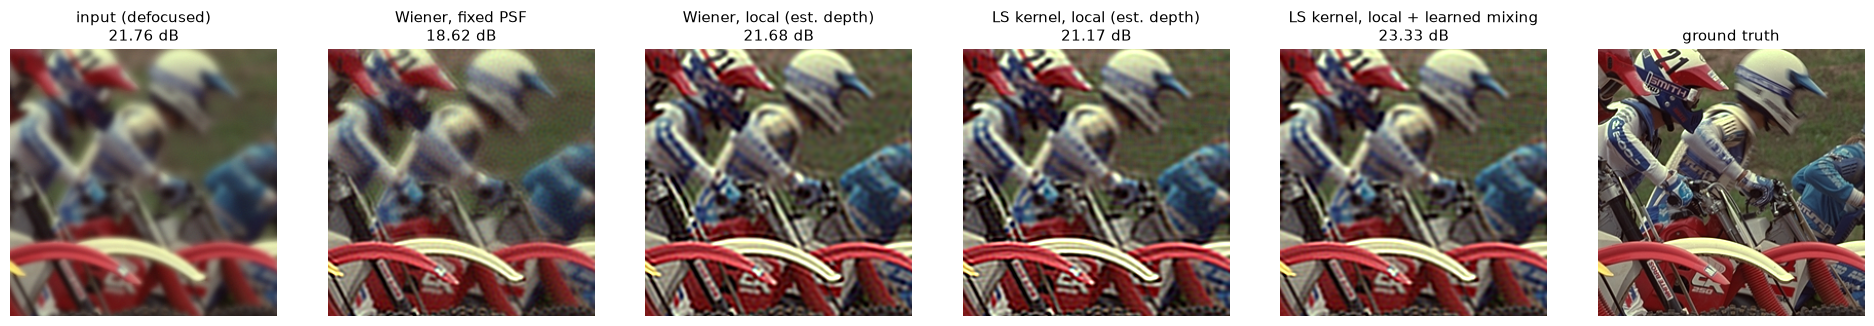

In [8]:
assert "scenes" in globals() and "out" in scenes["05"], "2〜4 のセルが実行されていません。上から順に実行してください（ランタイムが再起動した場合も最初から）"
s05 = scenes["05"]
o, g = s05["out"], s05["gt"]
names = ["input (defocused)", "Wiener, fixed PSF", "Wiener, local (est. depth)", "LS kernel, local (est. depth)", "LS kernel, local + learned mixing"]
box = (slice(30, 290), slice(380, 640))                   # 奥の選手（ボケが大きい所）を拡大
show([np.clip(o[n][box], 0, 1) for n in names] + [g[box]], [f"{n}\n{P(o[n], g):.2f} dB" for n in names] + ["ground truth"], size=3.2)

## 6. 画素ごとに直接予測する CNN と比べる
混ぜ方の重みと同じ「奥行き由来のボケ」（学習画像 3 枚 × ピント位置 6 通り）で、小さな CNN（12 層、約 37 万パラメータ）に「ボケ画像 → 鮮明画像」を直接学習させます。
CNN には奥行きを与えません（ボケの大きさも画像から自分で判断する）。T4 で約 8〜15 分かかるので、不要なら `RUN_CNN = False` にしてください。
（学習を長くしすぎると、学習画像 3 枚に過学習して、かえって下がります）

CNN のパラメータ数: 374k（逆カーネル＋混ぜ方の重みは 7.8k）


iter 0  loss 0.17166  (0s)


iter 1000  loss 0.00306  (65s)


iter 2000  loss 0.00292  (130s)


iter 3000  loss 0.00453  (195s)


iter 4000  loss 0.00459  (261s)


iter 5000  loss 0.00249  (326s)


学習 392s
PSNR (dB)                              05  08  21   mean
input (defocused)                      21.76 20.25 24.45  22.15
LS kernel, local (est. depth)          21.17 20.84 24.73  22.24
LS kernel, local + learned mixing      23.33 22.34 26.24  23.97
LS kernel, local (true depth)          23.57 22.55 26.52  24.21
CNN (per-pixel)                        23.10 21.82 26.30  23.74


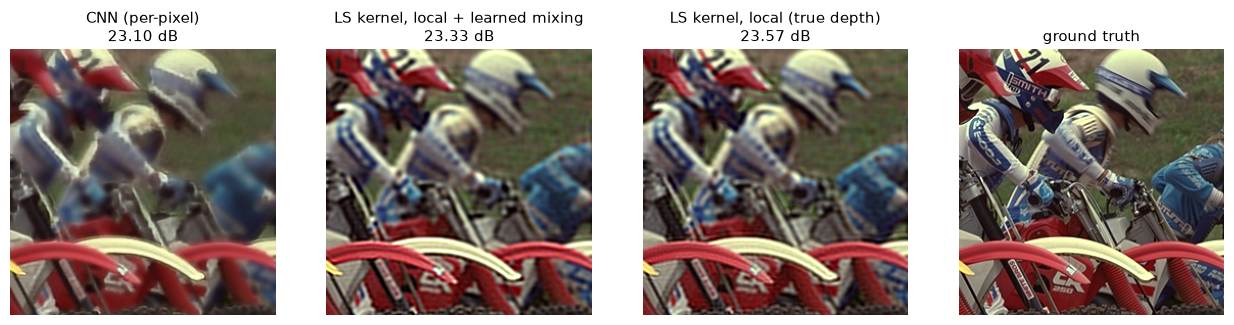

In [9]:
RUN_CNN = True
if RUN_CNN:
    import torch.nn as nn
    torch.manual_seed(0)
    class SmallCNN(nn.Module):
        def __init__(self, ch=64, L=12):
            super().__init__()
            layers = [nn.Conv2d(3, ch, 3, padding=1), nn.ReLU(True)]
            for _ in range(L - 2):
                layers += [nn.Conv2d(ch, ch, 3, padding=1), nn.BatchNorm2d(ch), nn.ReLU(True)]
            self.f = nn.Sequential(*layers, nn.Conv2d(ch, 3, 3, padding=1))
        def forward(self, x):
            return x + self.f(x)                                  # 入力との差（残差）を学習
    net = SmallCNN().to(DEVICE)
    n_ls = len(kernels) * KS * KS + W_mix.size
    print(f"CNN のパラメータ数: {sum(p.numel() for p in net.parameters())/1e3:.0f}k（逆カーネル＋混ぜ方の重みは {n_ls/1e3:.1f}k）")
    pairs = []                                                    # 混ぜ方の重みと同じ「奥行き由来のボケ」（3 枚 × ピント位置 6 通り）
    for x in train_imgs:
        D = disparity(x)
        for df in (1.0, 0.9, 0.8, 0.7, 0.6, 0.5):
            pairs.append((sv_blur(x, np.clip(A * np.abs(D - df), 0, 4)).astype(np.float32), x))
    rng = np.random.default_rng(0)
    def sample(Pz=96):
        b, x = pairs[rng.integers(len(pairs))]
        y0, x0 = rng.integers(0, x.shape[0] - Pz), rng.integers(0, x.shape[1] - Pz)
        bb = np.clip(b[y0:y0 + Pz, x0:x0 + Pz] + rng.normal(0, NOISE, (Pz, Pz, 3)), 0, 1)   # ノイズは小片ごとに加える
        return bb.astype(np.float32), x[y0:y0 + Pz, x0:x0 + Pz]
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    t0 = time.time()
    for it in range(6000):                                       # 先行研究との比較（スライド）と同じ 6,000 回
        bb, gg = zip(*[sample() for _ in range(16)])
        xb = torch.from_numpy(np.stack(bb)).permute(0, 3, 1, 2).to(DEVICE)
        xg = torch.from_numpy(np.stack(gg)).permute(0, 3, 1, 2).to(DEVICE)
        loss = nn.functional.mse_loss(net(xb), xg)
        opt.zero_grad(); loss.backward(); opt.step()
        if it == 4200:
            for g_ in opt.param_groups: g_["lr"] = 2e-4
        if it % 1000 == 0:
            print(f"iter {it}  loss {loss.item():.5f}  ({time.time()-t0:.0f}s)")
    net.eval()
    for t, sc in scenes.items():
        with torch.no_grad():
            sc["out"]["CNN (per-pixel)"] = net(to_tensor(sc["blur"].astype(np.float32)).to(DEVICE))[0].permute(1, 2, 0).cpu().numpy()
        res[t]["CNN (per-pixel)"] = P(sc["out"]["CNN (per-pixel)"], sc["gt"])
    print(f"学習 {time.time()-t0:.0f}s\nPSNR (dB)                              " + "  ".join(TESTS) + "   mean")
    for n in ["input (defocused)", "LS kernel, local (est. depth)", "LS kernel, local + learned mixing", "LS kernel, local (true depth)", "CNN (per-pixel)"]:
        v = [res[t][n] for t in TESTS]
        print(f"{n:38s} " + " ".join(f"{a:5.2f}" for a in v) + f"  {np.mean(v):5.2f}")
    o = s05["out"]
    cmp = ["CNN (per-pixel)", "LS kernel, local + learned mixing", "LS kernel, local (true depth)"]
    show([np.clip(o[n][box], 0, 1) for n in cmp] + [g[box]], [f"{n}\n{P(o[n], g):.2f} dB" for n in cmp] + ["ground truth"], size=3.2)

## まとめ
- **PSF が一定なら（論文の再現）**：同じ 15×15 の大きさでは、最小二乗の逆カーネルが Wiener を上回る。実際のボケがガウスでない（円盤状）と差はさらに大きい。
  PSF を正確に与えた理想的な Wiener（大きさ無制限）とはほぼ同等で、逆カーネルは PSF の式を知らずにデータだけでそこへ到達する
- **奥行きで PSF が変わると**：固定 PSF の手法は、手前を壊し、奥はボケが残るので、かえって悪化する
- **奥行き推定 × 場所ごとの逆カーネル**：奥行き推定の誤差（特に σ の見積もりすぎ）で性能が落ちるが、
  **誤差の傾向まで含めて混ぜ方を最小二乗法で学習** すると、正しい奥行きを使った場合に近づき、同じ学習画像 3 枚の CNN（約 37 万パラメータ）と同等以上になった（約 8 千係数）。
  スライドでは、先行研究（IFAN・KPAC・INIKNet・MultiWienerNet）も同じ条件で学習し直して比べている（IFAN・INIKNet とほぼ同等）。CNN の値は乱数で ±0.1 dB 程度ばらつく
- ただし先行研究（DPDD など大規模データ）では、画素ごとに直接予測する CNN が 2 段階法を上回っている。データが少ない・計算を軽くしたい・中身を説明したい場面で、逆カーネルの方法が有利
- ボケが大きい所（σ = 3〜4 画素）は、どの手法でも細部は戻らない（高い周波数の情報が、ノイズに埋もれて失われている）
- 実際のレンズのボケは円盤状で、収差により画面の端で形も変わる → PSF の式を仮定せず、キャリブレーション撮影の画像の組から逆カーネルを学習できるのが強み